# 04 · Comparativo, tendência e fatores de risco

| Seção | Conteúdo |
|---|---|
| 1 | **Crescimento dos sinistros?** Variação anual, CAGR e teste de tendência (Poisson) por município × via, e por modo (moto, pesado, bicicleta, pedestre) |
| 2 | Qualidade da série 2025: meses anômalos e sensibilidade (sem 2025; com notificações) |
| 3 | Taxa por 100 mil habitantes |
| 4 | Qui-quadrado + V de Cramér (Campinas × Guarulhos, e rodovia × via urbana) |
| 5 | Taxa de gravidade por fator de risco |
| 6 | **Regressão logística** (statsmodels): Odds Ratio, IC 95%, p-valor, AUC-ROC |
| 7 | Capotamento × tipo de via (modelos estratificados e interação) |
| 8 | Gravidade rodovia × via urbana e série mensal com média móvel |

Variável-alvo dos modelos: `grave_fatal` = 1 se o sinistro teve ao menos um ferido grave ou morto.

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import warnings; warnings.filterwarnings("ignore")
import polars as pl
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from src import config, estatistica, viz

viz.tema()
sin = pl.read_parquet(config.DATA_PROCESSED / "sinistros.parquet").to_pandas()
sin["grave_fatal_int"] = sin.grave_fatal.astype(int)
MUN, VIAS = config.MUNICIPIOS, config.GRUPOS_VIA
SEG = [(m, v) for m in MUN for v in VIAS]

## 1. Houve crescimento contínuo dos sinistros?
Para cada município × tipo de via calculamos:
- contagens anuais e variações 2022→2025 e 2024→2025;
- **CAGR** (taxa de crescimento anual composta) 2022–2025;
- **regressão de Poisson** na série mensal (`n ~ tempo + mês`), que dá a **razão de taxas anual
  (IRR)**: IRR > 1 = crescimento, IRR < 1 = queda; p < 0,05 = tendência estatisticamente significativa.
- "Crescimento contínuo" = aumento em **todos** os anos consecutivos.

In [2]:
def tabela_tendencia(df, rotulo, filtro=None):
    linhas = []
    for mun, via in SEG:
        d = df[(df.municipio == mun) & (df.grupo_via == via)]
        if filtro is not None:
            d = d[d[filtro]]
        anual = d.groupby("ano").size().reindex(config.ANOS, fill_value=0)
        mens = (d.groupby(["ano", "mes"]).size()
                  .reindex(pd.MultiIndex.from_product([config.ANOS, range(1, 13)], names=["ano", "mes"]),
                           fill_value=0).reset_index(name="n"))
        tp = estatistica.tendencia_poisson(mens)
        difs = np.diff(anual.values)
        linhas.append({"indicador": rotulo, "municipio": mun, "grupo_via": via,
                       **{str(a): int(anual[a]) for a in config.ANOS},
                       "var_22_25_pct": round((anual[2025] / anual[2022] - 1) * 100, 1),
                       "var_24_25_pct": round((anual[2025] / anual[2024] - 1) * 100, 1),
                       "cagr_pct": round(estatistica.cagr(anual[2022], anual[2025], 3) * 100, 1),
                       "irr_anual": round(tp["irr_anual"], 3), "irr_ic95": f"{tp['ic_inf']:.3f}–{tp['ic_sup']:.3f}",
                       "p_valor": round(tp["p_valor"], 4),
                       "crescimento_continuo": bool((difs > 0).all())})
    return pd.DataFrame(linhas)

tend = pd.concat([
    tabela_tendencia(sin, "Todos os sinistros com vítima"),
    tabela_tendencia(sin, "Sinistros fatais", "fatal"),
    tabela_tendencia(sin, "Envolve motocicleta", "envolve_moto"),
    tabela_tendencia(sin, "Envolve veículo pesado", "envolve_pesado"),
    tabela_tendencia(sin, "Envolve bicicleta", "envolve_bicicleta"),
    tabela_tendencia(sin, "Envolve pedestre", "envolve_pedestre"),
], ignore_index=True)
viz.salvar_tab(tend, "04_tendencia_crescimento")
tend

  ✔ tabela salva: reports/tables/04_tendencia_crescimento.csv


,indicador,municipio,grupo_via,2022,2023,2024,2025,var_22_25_pct,var_24_25_pct,cagr_pct,irr_anual,irr_ic95,p_valor,crescimento_continuo
0,Todos os sinistros com vítima,CAMPINAS,RODOVIA,1026,891,865,587,-42.8,-32.1,-17.0,0.852,0.818–0.886,0.0000,False
1,Todos os sinistros com vítima,CAMPINAS,VIA URBANA,2256,2543,2448,2003,-11.2,-18.2,-3.9,0.964,0.937–0.992,0.0115,False
2,Todos os sinistros com vítima,GUARULHOS,RODOVIA,1059,1173,1245,711,-32.9,-42.9,-12.4,0.911,0.852–0.975,0.0067,False
3,Todos os sinistros com vítima,GUARULHOS,VIA URBANA,2297,2379,2373,2002,-12.8,-15.6,-4.5,0.961,0.943–0.980,0.0001,False
4,Sinistros fatais,CAMPINAS,RODOVIA,67,76,82,69,3.0,-15.9,1.0,1.016,0.935–1.105,0.7003,False
5,Sinistros fatais,CAMPINAS,VIA URBANA,68,67,66,73,7.4,10.6,2.4,1.021,0.940–1.109,0.6287,False
6,Sinistros fatais,GUARULHOS,RODOVIA,50,61,55,53,6.0,-3.6,2.0,1.005,0.917–1.103,0.9075,False
7,Sinistros fatais,GUARULHOS,VIA URBANA,79,60,104,86,8.9,-17.3,2.9,1.082,0.993–1.180,0.0717,False
8,Envolve motocicleta,CAMPINAS,RODOVIA,560,504,507,370,-33.9,-27.0,-12.9,0.889,0.854–0.926,0.0000,False
9,Envolve motocicleta,CAMPINAS,VIA URBANA,1232,1274,1400,1356,10.1,-3.1,3.2,1.039,1.014–1.064,0.0023,False


In [3]:
def frase(r):
    sentido = "crescimento" if r.irr_anual > 1 else "queda"
    sig = "significativa" if r.p_valor < 0.05 else "NÃO significativa"
    cont = "houve" if r.crescimento_continuo else "NÃO houve"
    return (f"{r.municipio.title()} – {r.grupo_via}: {r['2022']:,} → {r['2025']:,} "
            f"({r.var_22_25_pct:+.1f}%); tendência de {sentido} {sig} "
            f"(IRR {r.irr_anual:.3f}, p={r.p_valor:.4f}); {cont} crescimento contínuo.")

print("CONCLUSÃO (todos os sinistros com vítima):")
for _, r in tend[tend.indicador == "Todos os sinistros com vítima"].iterrows():
    print(" •", frase(r))

CONCLUSÃO (todos os sinistros com vítima):
 • Campinas – RODOVIA: 1,026 → 587 (-42.8%); tendência de queda significativa (IRR 0.852, p=0.0000); NÃO houve crescimento contínuo.
 • Campinas – VIA URBANA: 2,256 → 2,003 (-11.2%); tendência de queda significativa (IRR 0.964, p=0.0115); NÃO houve crescimento contínuo.
 • Guarulhos – RODOVIA: 1,059 → 711 (-32.9%); tendência de queda significativa (IRR 0.911, p=0.0067); NÃO houve crescimento contínuo.
 • Guarulhos – VIA URBANA: 2,297 → 2,002 (-12.8%); tendência de queda significativa (IRR 0.961, p=0.0001); NÃO houve crescimento contínuo.


**Gráfico:** à esquerda, índice anual (2022 = 100) para os 4 segmentos; à direita, IRR anual com
IC 95% (linha tracejada = 1, sem tendência) para cada indicador.

  ✔ figura salva: reports/figures/04_tendencia_crescimento.png


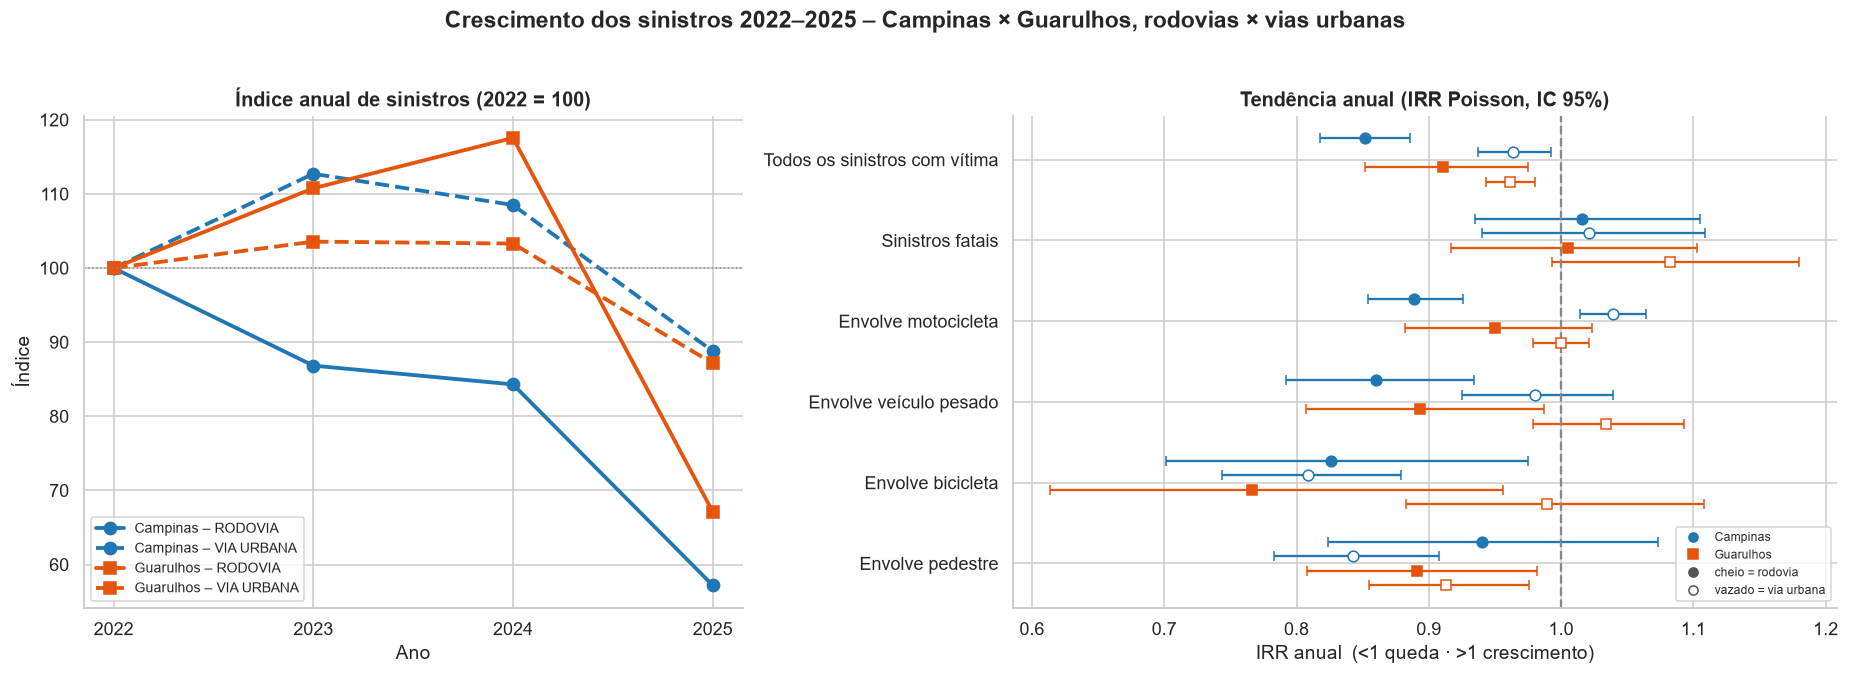

In [4]:
t0 = tend[tend.indicador == "Todos os sinistros com vítima"]
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
for _, r in t0.iterrows():
    v = np.array([r[str(a)] for a in config.ANOS]) / r["2022"] * 100
    ax.plot(config.ANOS, v, color=config.CORES[r.municipio], lw=2.5, ms=8,
            marker="o" if r.municipio == "CAMPINAS" else "s",
            ls="-" if r.grupo_via == "RODOVIA" else "--", label=f"{r.municipio.title()} – {r.grupo_via}")
ax.axhline(100, color="#888", ls=":", lw=1)
ax.set(title="Índice anual de sinistros (2022 = 100)", xlabel="Ano", ylabel="Índice", xticks=config.ANOS)
ax.legend(fontsize=9)

ax = axes[1]
tt = tend.copy()
tt["lo"] = tt.irr_ic95.str.split("–").str[0].astype(float)
tt["hi"] = tt.irr_ic95.str.split("–").str[1].astype(float)
inds = tt.indicador.unique()
desl = {s: k for k, s in enumerate(SEG)}
for i, ind in enumerate(inds):
    for _, r in tt[tt.indicador == ind].iterrows():
        y = i + (desl[(r.municipio, r.grupo_via)] - 1.5) * 0.18
        ax.errorbar(r.irr_anual, y, xerr=[[r.irr_anual - r.lo], [r.hi - r.irr_anual]], fmt="o" if r.municipio == "CAMPINAS" else "s",
                    color=config.CORES[r.municipio], mfc=config.CORES[r.municipio] if r.grupo_via == "RODOVIA" else "white",
                    ms=7, capsize=3, lw=1.5)
ax.axvline(1, ls="--", color="#888")
ax.set_yticks(range(len(inds))); ax.set_yticklabels(inds); ax.invert_yaxis()
ax.set(title="Tendência anual (IRR Poisson, IC 95%)", xlabel="IRR anual  (<1 queda · >1 crescimento)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", color=config.CORES["CAMPINAS"], ls="", label="Campinas"),
                   Line2D([], [], marker="s", color=config.CORES["GUARULHOS"], ls="", label="Guarulhos"),
                   Line2D([], [], marker="o", color="#555", ls="", label="cheio = rodovia"),
                   Line2D([], [], marker="o", mfc="white", color="#555", ls="", label="vazado = via urbana")],
          fontsize=8, loc="lower right")
fig.suptitle("Crescimento dos sinistros 2022–2025 – Campinas × Guarulhos, rodovias × vias urbanas",
             fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "04_tendencia_crescimento"); plt.show()

## 2. Qualidade da série em 2025 e análise de sensibilidade
Um mês é marcado como **anômalo** quando tem menos de 50% da mediana dos 12 meses anteriores
do mesmo segmento — sinal de possível sub-registro ou atraso de digitação, não de queda real.

In [5]:
mens = (sin.groupby(["municipio", "grupo_via", "ano_mes"]).size().rename("n").reset_index()
           .sort_values(["municipio", "grupo_via", "ano_mes"]))
mens["mediana_12m_ant"] = (mens.groupby(["municipio", "grupo_via"]).n
                              .transform(lambda s: s.shift(1).rolling(12, min_periods=6).median()))
mens["anomalo"] = mens.n < 0.5 * mens.mediana_12m_ant
anom = mens[mens.anomalo]
viz.salvar_tab(anom, "04_meses_anomalos")
print(f"Meses anômalos detectados: {len(anom)}")
anom

  ✔ tabela salva: reports/tables/04_meses_anomalos.csv
Meses anômalos detectados: 4


,municipio,grupo_via,ano_mes,n,mediana_12m_ant,anomalo
37,CAMPINAS,RODOVIA,2025-02,36,74.0,True
137,GUARULHOS,RODOVIA,2025-06,22,102.0,True
138,GUARULHOS,RODOVIA,2025-07,17,100.0,True
139,GUARULHOS,RODOVIA,2025-08,13,89.0,True


**Sensibilidade 1 – só 2022–2024** (exclui 2025, que contém os meses anômalos).
**Sensibilidade 2 – incluindo `NOTIFICACAO`** (registros sem vítima), para ver se a queda de 2025
nos sinistros com vítima é compensada por aumento das notificações (mudança de classificação).

In [6]:
bruto = pl.read_parquet(config.DATA_INTERIM / "sinistros_bruto.parquet",
                        columns=["municipio", "tipo_registro", "tipo_via", "ano_sinistro"]).to_pandas()
bruto = bruto[bruto.municipio.isin(MUN) & bruto.tipo_via.isin(config.GRUPO_VIA)
              & bruto.ano_sinistro.isin([str(a) for a in config.ANOS])]
bruto["grupo_via"] = bruto.tipo_via.map(config.GRUPO_VIA)
reg_ano = (bruto.groupby(["municipio", "grupo_via", "tipo_registro", "ano_sinistro"]).size()
                .unstack(fill_value=0).reset_index())
viz.salvar_tab(reg_ano, "04_registros_por_tipo_ano")
display(reg_ano)

sens = []
for mun, via in SEG:
    a = sin[(sin.municipio == mun) & (sin.grupo_via == via)].groupby("ano").size()
    b = bruto[(bruto.municipio == mun) & (bruto.grupo_via == via)].groupby("ano_sinistro").size()
    b.index = b.index.astype(int)
    sens.append({"municipio": mun, "grupo_via": via,
                 "var_22_24_com_vitima_pct": round((a[2024] / a[2022] - 1) * 100, 1),
                 "crescimento_continuo_22_24": bool(a[2023] > a[2022] and a[2024] > a[2023]),
                 "var_22_25_todos_registros_pct": round((b[2025] / b[2022] - 1) * 100, 1),
                 "crescimento_continuo_todos_registros": bool((np.diff(b.reindex(config.ANOS).values) > 0).all())})
sens = pd.DataFrame(sens)
viz.salvar_tab(sens, "04_sensibilidade_tendencia")
sens

  ✔ tabela salva: reports/tables/04_registros_por_tipo_ano.csv


ano_sinistro,municipio,grupo_via,tipo_registro,2022,2023,2024,2025
0,CAMPINAS,RODOVIA,NOTIFICACAO,331,451,384,366
1,CAMPINAS,RODOVIA,SINISTRO FATAL,67,76,82,69
2,CAMPINAS,RODOVIA,SINISTRO NAO FATAL,959,815,783,518
3,CAMPINAS,VIA URBANA,NOTIFICACAO,947,1127,1154,2098
4,CAMPINAS,VIA URBANA,SINISTRO FATAL,68,67,66,73
5,CAMPINAS,VIA URBANA,SINISTRO NAO FATAL,2188,2476,2382,1930
6,GUARULHOS,RODOVIA,NOTIFICACAO,509,478,449,179
7,GUARULHOS,RODOVIA,SINISTRO FATAL,50,61,55,53
8,GUARULHOS,RODOVIA,SINISTRO NAO FATAL,1009,1112,1190,658
9,GUARULHOS,VIA URBANA,NOTIFICACAO,1333,1429,1611,1963


  ✔ tabela salva: reports/tables/04_sensibilidade_tendencia.csv


,municipio,grupo_via,var_22_24_com_vitima_pct,crescimento_continuo_22_24,var_22_25_todos_registros_pct,crescimento_continuo_todos_registros
0,CAMPINAS,RODOVIA,-15.7,False,-29.8,False
1,CAMPINAS,VIA URBANA,8.5,False,28.0,False
2,GUARULHOS,RODOVIA,17.6,True,-43.2,False
3,GUARULHOS,VIA URBANA,3.3,False,9.2,False


## 3. Taxa por 100 mil habitantes (Censo IBGE 2022)
> Cautela: em rodovias o risco depende do tráfego de passagem, não só da população residente.

In [7]:
taxa = (sin.groupby(["municipio", "grupo_via", "ano"])
           .agg(sinistros=("id_sinistro", "count"), fatais=("fatal", "sum")).reset_index())
taxa["pop"] = taxa.municipio.map(config.POPULACAO)
taxa["sin_100k"] = (taxa.sinistros / taxa["pop"] * 1e5).round(1)
taxa["fat_100k"] = (taxa.fatais / taxa["pop"] * 1e5).round(2)
viz.salvar_tab(taxa, "04_taxa_100k")
taxa.pivot_table(index=["municipio", "grupo_via"], columns="ano", values=["sin_100k", "fat_100k"])

  ✔ tabela salva: reports/tables/04_taxa_100k.csv


fat_100k                   sin_100k                     
ano                      2022  2023  2024  2025     2022   2023   2024   2025
municipio grupo_via                                                          
CAMPINAS  RODOVIA        5.88  6.67  7.20  6.06     90.1   78.2   75.9   51.5
          VIA URBANA     5.97  5.88  5.79  6.41    198.1  223.3  214.9  175.8
GUARULHOS RODOVIA        3.87  4.72  4.26  4.10     82.0   90.8   96.4   55.0
          VIA URBANA     6.12  4.64  8.05  6.66    177.8  184.2  183.7  155.0

## 4. Qui-quadrado e V de Cramér
**H₀:** a distribuição da variável é igual nos dois grupos comparados.
V de Cramér: ≈0,1 pequeno · ≈0,3 médio · ≥0,5 grande. Com n grande, p-valores pequenos são comuns;
o **tamanho do efeito (V)** é o que indica relevância prática.

In [8]:
variaveis = ["gravidade", "periodo", "dia_semana", "fim_semana", "tipo_detalhado",
             "envolve_moto", "envolve_pesado", "envolve_bicicleta", "envolve_pedestre", "tp_capotamento"]
qui = []
for via in VIAS:
    d = sin[sin.grupo_via == via]
    qui += [{**estatistica.qui_quadrado(d, v, "municipio"), "comparacao": f"Campinas × Guarulhos ({via})"}
            for v in variaveis]
for mun in MUN:
    d = sin[sin.municipio == mun]
    qui += [{**estatistica.qui_quadrado(d, v, "grupo_via"), "comparacao": f"Rodovia × Via urbana ({mun})"}
            for v in variaveis]
qui = pd.DataFrame(qui)
qui["significativo_5pct"] = qui.p_valor < 0.05
viz.salvar_tab(qui, "04_qui_quadrado")
qui.pivot_table(index="variavel", columns="comparacao", values="cramer_v").round(3)

  ✔ tabela salva: reports/tables/04_qui_quadrado.csv


comparacao,Campinas × Guarulhos (RODOVIA),Campinas × Guarulhos (VIA URBANA),Rodovia × Via urbana (CAMPINAS),Rodovia × Via urbana (GUARULHOS)
variavel,,,,
dia_semana,0.035,0.026,0.024,0.062
envolve_bicicleta,0.002,0.015,0.013,0.025
envolve_moto,0.073,0.074,0.006,0.005
envolve_pedestre,0.019,0.087,0.058,0.118
envolve_pesado,0.020,0.018,0.077,0.083
fim_semana,0.025,0.022,0.015,0.059
gravidade,0.295,0.099,0.155,0.296
periodo,0.040,0.046,0.102,0.098
tipo_detalhado,0.357,0.137,0.579,0.478


## 5. Taxa de gravidade por fator de risco
% de sinistros graves ou fatais em cada nível do fator, por município, separado por tipo de via.
Só níveis com n ≥ 30 sinistros.

  ✔ tabela salva: reports/tables/04_taxa_gravidade_fatores.csv


  ✔ figura salva: reports/figures/04_taxa_gravidade_fatores.png


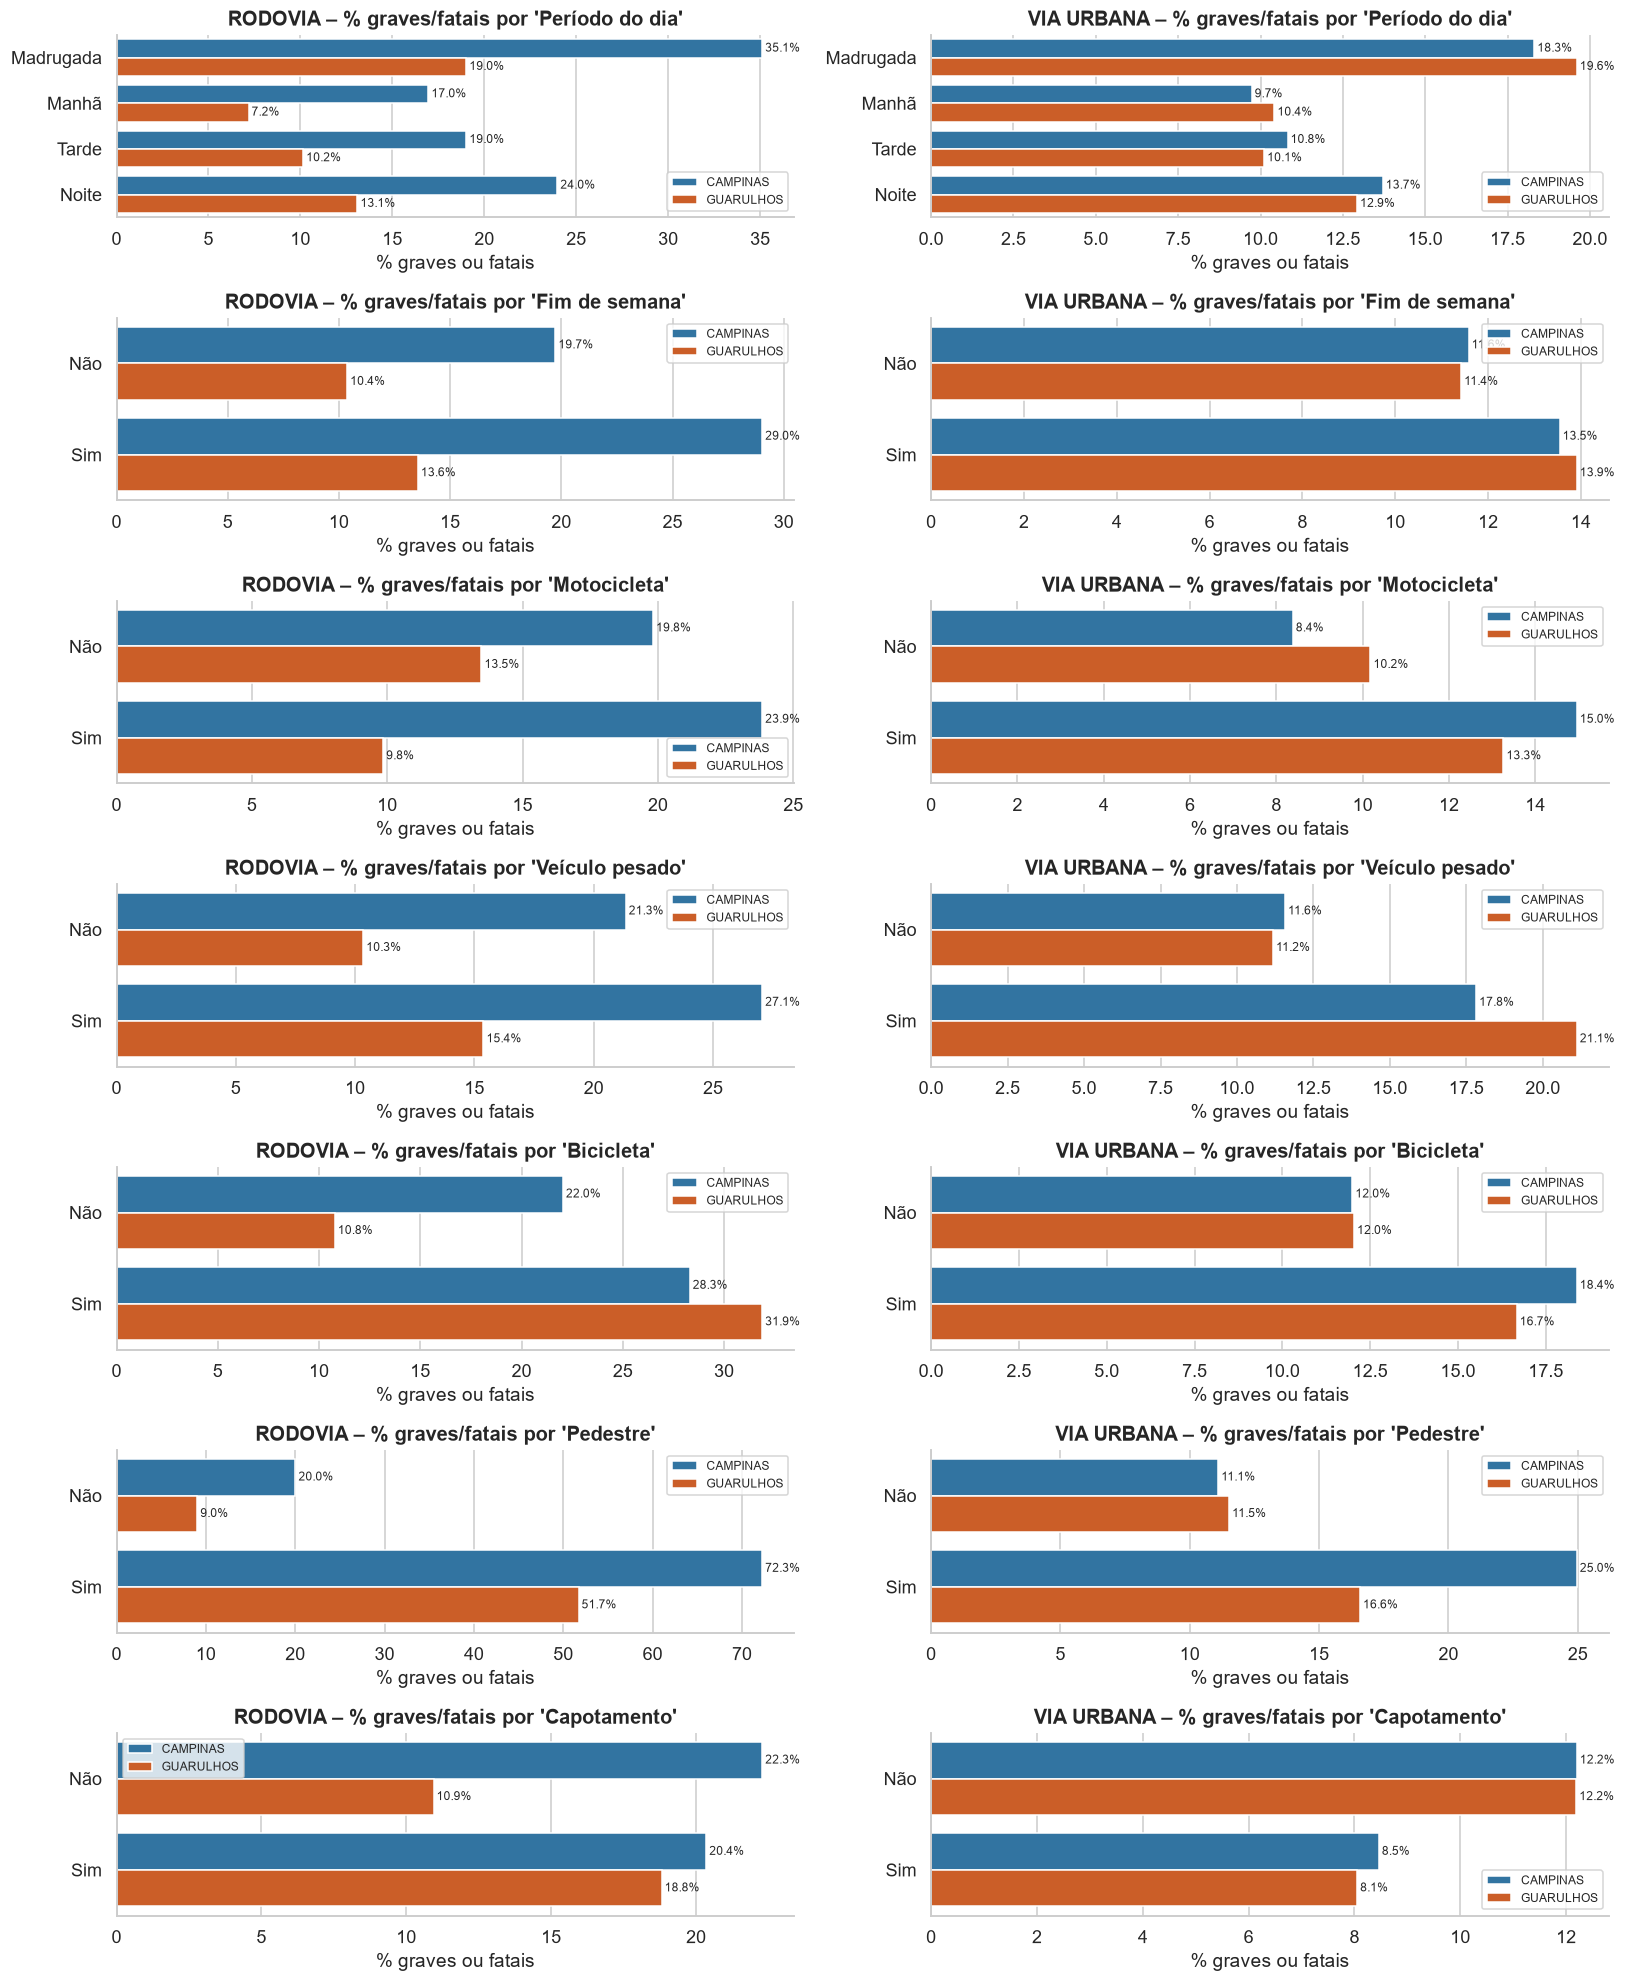

In [9]:
sin["periodo_f"] = sin.periodo
sim_nao = {True: "Sim", False: "Não"}
fatores = {"periodo_f": "Período do dia", "fim_semana": "Fim de semana", "envolve_moto": "Motocicleta",
           "envolve_pesado": "Veículo pesado", "envolve_bicicleta": "Bicicleta",
           "envolve_pedestre": "Pedestre", "tp_capotamento": "Capotamento"}
fig, axes = plt.subplots(len(fatores), 2, figsize=(15, 2.6 * len(fatores)))
todas = []
for i, (f, rot) in enumerate(fatores.items()):
    t = estatistica.tabela_risco(sin, f, "grave_fatal_int", grupos=("grupo_via", "municipio"))
    t["nivel"] = t[f].map(sim_nao) if t[f].dtype == bool else t[f]
    todas.append(t.assign(fator=rot).drop(columns=[f]))
    ordem = config.ORDEM_PERIODOS if f == "periodo_f" else ["Não", "Sim"]
    for j, via in enumerate(VIAS):
        ax = axes[i, j]
        d = t[t.grupo_via == via]
        sns.barplot(data=d, y="nivel", x="pct", hue="municipio", hue_order=MUN,
                    order=[o for o in ordem if o in set(d.nivel)], palette=config.CORES, ax=ax)
        viz.rotulos_pct(ax, fontsize=8)
        ax.set(title=f"{via} – % graves/fatais por '{rot}'", xlabel="% graves ou fatais", ylabel="")
        ax.legend(fontsize=8, title="")
risco = pd.concat(todas, ignore_index=True)
viz.salvar_tab(risco, "04_taxa_gravidade_fatores")
plt.tight_layout(); viz.salvar_fig(fig, "04_taxa_gravidade_fatores"); plt.show()

## 6. Regressão logística – Odds Ratios
Modelo: `grave_fatal ~ município + tipo de via + período + fim de semana + ano + modos + tipos`.

**Categorias de referência:** Campinas, Via urbana, Manhã, dia útil, ano 2022, sem o modo/tipo.
**OR > 1** = maior chance de o sinistro ser grave/fatal, mantidas as demais variáveis constantes.

Colinearidade: `envolve_pedestre` e `tp_atropelamento` têm correlação muito alta
(valor calculado na célula abaixo) — medem praticamente a mesma coisa, então só `envolve_pedestre`
entra no modelo. Os VIFs das demais variáveis são verificados.

In [10]:
base = sin.dropna(subset=["periodo"]).copy()
X = pd.DataFrame({
    "Guarulhos": (base.municipio == "GUARULHOS"),
    "Rodovia": (base.grupo_via == "RODOVIA"),
    "Madrugada": base.periodo == "Madrugada", "Tarde": base.periodo == "Tarde", "Noite": base.periodo == "Noite",
    "Fim de semana": base.fim_semana,
    "Ano 2023": base.ano == 2023, "Ano 2024": base.ano == 2024, "Ano 2025": base.ano == 2025,
    "Motocicleta": base.envolve_moto, "Veículo pesado": base.envolve_pesado,
    "Bicicleta": base.envolve_bicicleta, "Pedestre": base.envolve_pedestre,
    "Capotamento": base.tp_capotamento, "Tombamento": base.tp_tombamento,
    "Colisão frontal": base.tp_colisao_frontal, "Colisão lateral": base.tp_colisao_lateral,
    "Colisão transversal": base.tp_colisao_transv, "Choque": base.tp_choque,
    "Engavetamento": base.tp_engavetamento,
}).astype(float)
y = base.grave_fatal_int.values
r_ped = np.corrcoef(base.envolve_pedestre, base.tp_atropelamento)[0, 1]
print(f"Correlação envolve_pedestre × tp_atropelamento = {r_ped:.2f}")

Xc = sm.add_constant(X)
vif = pd.DataFrame({"variavel": X.columns,
                    "VIF": [round(variance_inflation_factor(Xc.values, i + 1), 2) for i in range(X.shape[1])]})
print("Maior VIF:", vif.VIF.max()); display(vif.sort_values("VIF", ascending=False).head(5))

logit = sm.Logit(y, Xc).fit(disp=False)
ci = logit.conf_int()
or_df = pd.DataFrame({"termo": X.columns, "OR": np.exp(logit.params[1:]).values,
                      "IC95_inf": np.exp(ci.iloc[1:, 0]).values, "IC95_sup": np.exp(ci.iloc[1:, 1]).values,
                      "p_valor": logit.pvalues[1:].values}).round(4)
or_df["significativo"] = or_df.p_valor < 0.05
or_df = or_df.sort_values("OR").reset_index(drop=True)
viz.salvar_tab(or_df, "04_odds_ratios")
print(f"n = {int(logit.nobs):,} | pseudo-R² (McFadden) = {logit.prsquared:.4f}")
or_df

Correlação envolve_pedestre × tp_atropelamento = 0.93


Maior VIF: 1.5


,variavel,VIF
6,Ano 2023,1.50
7,Ano 2024,1.50
8,Ano 2025,1.45
4,Noite,1.43
16,Colisão lateral,1.42


  ✔ tabela salva: reports/tables/04_odds_ratios.csv
n = 25,820 | pseudo-R² (McFadden) = 0.0769


,termo,OR,IC95_inf,IC95_sup,p_valor,significativo
0,Engavetamento,0.5784,0.3846,0.8699,0.0086,True
1,Colisão lateral,0.6199,0.5578,0.6889,0.0000,True
2,Guarulhos,0.6699,0.6198,0.7241,0.0000,True
3,Colisão transversal,0.8208,0.7337,0.9183,0.0006,True
4,Ano 2023,0.9583,0.8626,1.0647,0.4280,False
5,Ano 2024,1.0675,0.9627,1.1838,0.2154,False
6,Tarde,1.0774,0.9710,1.1955,0.1597,False
7,Tombamento,1.1565,1.0207,1.3102,0.0225,True
8,Ano 2025,1.1682,1.0476,1.3027,0.0052,True
9,Fim de semana,1.2853,1.1824,1.3970,0.0000,True


**AUC-ROC da regressão logística** — avaliada fora da amostra, com a mesma divisão 80/20
estratificada (semente 42) usada no Random Forest do notebook 06, para comparação justa.

In [11]:
Xtr, Xte, ytr, yte = train_test_split(Xc, y, test_size=0.2, random_state=config.SEED, stratify=y)
logit_tr = sm.Logit(ytr, Xtr).fit(disp=False)
p_te = logit_tr.predict(Xte)
auc_log = roc_auc_score(yte, p_te)
auc_log_in = roc_auc_score(y, logit.predict(Xc))
pd.DataFrame([{"modelo": "Regressão logística", "auc_teste": round(auc_log, 4),
               "auc_in_sample": round(auc_log_in, 4), "n_teste": len(yte),
               "pseudo_r2": round(logit.prsquared, 4)}]).to_csv(config.TAB_DIR / "04_auc_logistica.csv", index=False)
print(f"AUC-ROC (teste 20%) = {auc_log:.3f} | AUC in-sample = {auc_log_in:.3f}")

AUC-ROC (teste 20%) = 0.699 | AUC in-sample = 0.701


  ✔ figura salva: reports/figures/04_odds_ratios.png


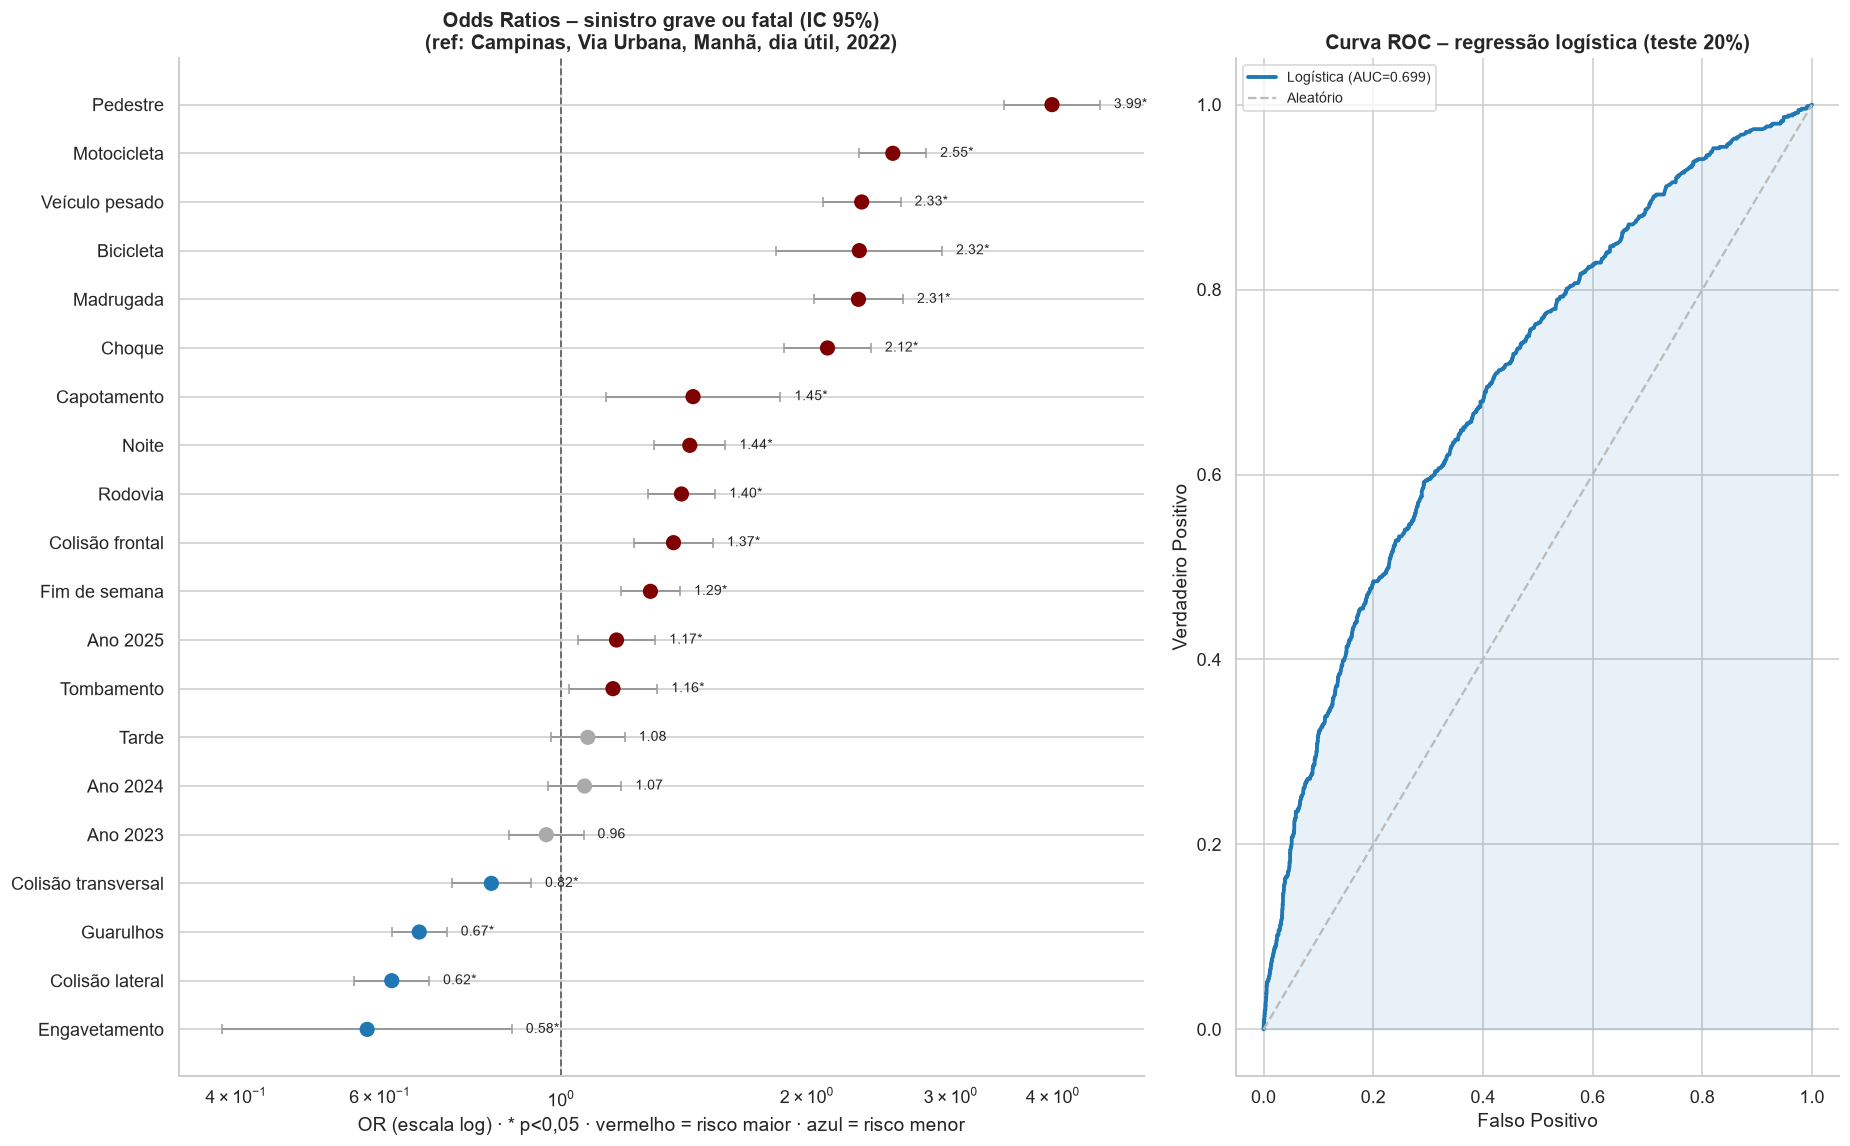

In [12]:
cor_or = ["#7f0000" if (r.OR > 1 and r.significativo) else "#1f77b4" if (r.OR < 1 and r.significativo)
          else "#aaaaaa" for r in or_df.itertuples()]
fig, axes = plt.subplots(1, 2, figsize=(17, 0.42 * len(or_df) + 2.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.errorbar(or_df.OR, range(len(or_df)), xerr=[or_df.OR - or_df.IC95_inf, or_df.IC95_sup - or_df.OR],
            fmt="none", ecolor="#999", capsize=3, lw=1.3, zorder=2)
ax.scatter(or_df.OR, range(len(or_df)), c=cor_or, s=80, zorder=3)
for k, r in enumerate(or_df.itertuples()):
    ax.text(r.IC95_sup * 1.04, k, f"{r.OR:.2f}{'*' if r.significativo else ''}", va="center", fontsize=9)
ax.axvline(1, ls="--", color="#666", lw=1.2)
ax.set_xscale("log"); ax.set_yticks(range(len(or_df))); ax.set_yticklabels(or_df.termo)
ax.set(title="Odds Ratios – sinistro grave ou fatal (IC 95%)\n(ref: Campinas, Via Urbana, Manhã, dia útil, 2022)",
       xlabel="OR (escala log) · * p<0,05 · vermelho = risco maior · azul = risco menor")
ax = axes[1]
fpr, tpr, _ = roc_curve(yte, p_te)
ax.plot(fpr, tpr, lw=2.5, color="#1f77b4", label=f"Logística (AUC={auc_log:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#bbb", label="Aleatório")
ax.fill_between(fpr, tpr, alpha=.1, color="#1f77b4")
ax.set(title="Curva ROC – regressão logística (teste 20%)", xlabel="Falso Positivo", ylabel="Verdadeiro Positivo")
ax.legend(fontsize=9)
plt.tight_layout(); viz.salvar_fig(fig, "04_odds_ratios"); plt.show()

## 7. Capotamento × tipo de via
Pergunta: o capotamento é igualmente perigoso em rodovias e em vias urbanas, e nas duas cidades?
(a) % graves/fatais em sinistros com e sem capotamento; (b) mesmo modelo logístico ajustado
**separadamente** em rodovias e em vias urbanas; (c) termo de **interação** capotamento × rodovia
no modelo completo.

In [13]:
cap = (sin.groupby(["municipio", "grupo_via", "tp_capotamento"])
          .agg(n=("id_sinistro", "count"), gf=("grave_fatal", "sum"), fat=("fatal", "sum")).reset_index())
cap["pct_gf"] = (cap.gf / cap.n * 100).round(1); cap["pct_fatal"] = (cap.fat / cap.n * 100).round(1)
viz.salvar_tab(cap, "04_capotamento_via")
display(cap)

cols_mod = [c for c in X.columns if c != "Rodovia"]
estrat = []
for via in VIAS:
    m = (base.grupo_via == via).values
    Xv = X.loc[m, cols_mod]
    Xv = sm.add_constant(Xv.loc[:, Xv.std() > 0])
    lv = sm.Logit(y[m], Xv).fit(disp=False)
    civ = lv.conf_int()
    estrat.append(pd.DataFrame({"grupo_via": via, "termo": lv.params.index,
                                "OR": np.exp(lv.params), "IC95_inf": np.exp(civ[0]), "IC95_sup": np.exp(civ[1]),
                                "p_valor": lv.pvalues}).query("termo != 'const'"))
estrat = pd.concat(estrat).round(4).reset_index(drop=True)
viz.salvar_tab(estrat, "04_odds_ratios_por_via")

Xi = Xc.assign(**{"Capotamento × Rodovia": X["Capotamento"] * X["Rodovia"]})
li = sm.Logit(y, Xi).fit(disp=False)
p_int = li.pvalues["Capotamento × Rodovia"]; or_int = np.exp(li.params["Capotamento × Rodovia"])
print(f"Interação capotamento × rodovia: OR = {or_int:.3f}, p = {p_int:.4f} "
      f"→ {'o efeito do capotamento DIFERE' if p_int < 0.05 else 'sem evidência de que o efeito do capotamento difira'} "
      "entre rodovia e via urbana.")

  ✔ tabela salva: reports/tables/04_capotamento_via.csv


,municipio,grupo_via,tp_capotamento,n,gf,fat,pct_gf,pct_fatal
0,CAMPINAS,RODOVIA,False,3138,699,281,22.3,9.0
1,CAMPINAS,RODOVIA,True,231,47,13,20.3,5.6
2,CAMPINAS,VIA URBANA,False,9049,1104,268,12.2,3.0
3,CAMPINAS,VIA URBANA,True,201,17,6,8.5,3.0
4,GUARULHOS,RODOVIA,False,4087,447,209,10.9,5.1
5,GUARULHOS,RODOVIA,True,101,19,10,18.8,9.9
6,GUARULHOS,VIA URBANA,False,8964,1093,326,12.2,3.6
7,GUARULHOS,VIA URBANA,True,87,7,3,8.0,3.4


  ✔ tabela salva: reports/tables/04_odds_ratios_por_via.csv


Interação capotamento × rodovia: OR = 1.690, p = 0.0465 → o efeito do capotamento DIFERE entre rodovia e via urbana.


  ✔ figura salva: reports/figures/04_odds_ratios_por_via.png


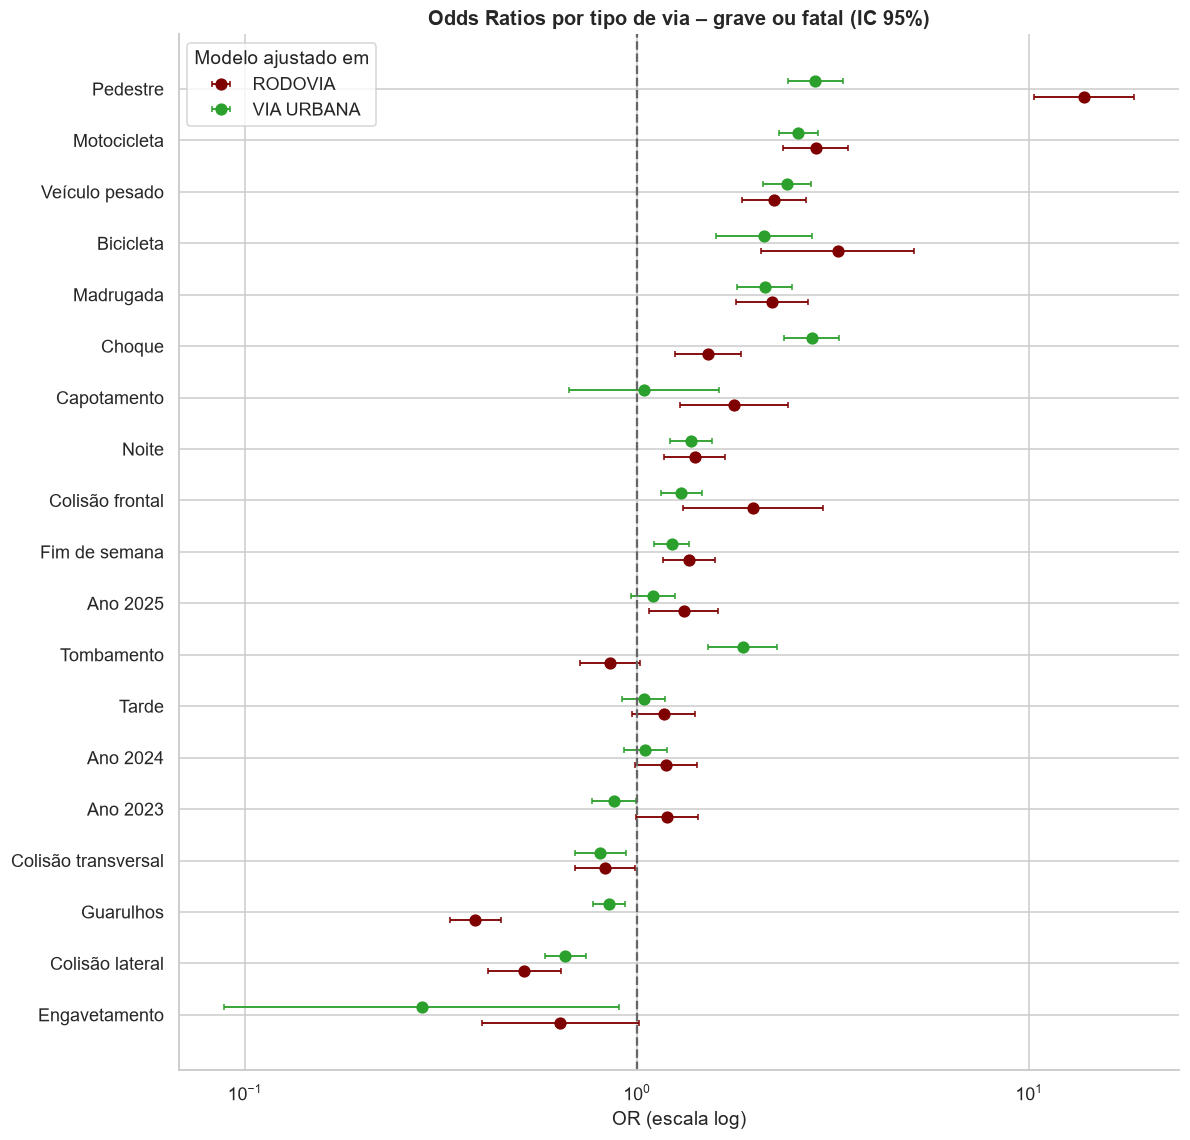

In [14]:
termos = [t for t in or_df.termo if t not in ("Rodovia",)]
fig, ax = plt.subplots(figsize=(11, 0.45 * len(termos) + 2))
for k, via in enumerate(VIAS):
    d = estrat[estrat.grupo_via == via].set_index("termo").reindex(termos)
    yy = np.arange(len(termos)) + (k - .5) * 0.3
    ax.errorbar(d.OR, yy, xerr=[d.OR - d.IC95_inf, d.IC95_sup - d.OR], fmt="o", ms=7,
                color=config.CORES_VIA[via], capsize=2, lw=1.2, label=via)
ax.axvline(1, ls="--", color="#666"); ax.set_xscale("log")
ax.set_yticks(range(len(termos))); ax.set_yticklabels(termos)
ax.set(title="Odds Ratios por tipo de via – grave ou fatal (IC 95%)",
       xlabel="OR (escala log)")
ax.legend(title="Modelo ajustado em")
plt.tight_layout(); viz.salvar_fig(fig, "04_odds_ratios_por_via"); plt.show()

## 8. Gravidade: rodovia × via urbana, e série mensal com média móvel

  ✔ figura salva: reports/figures/04_comparativo_via_gravidade.png


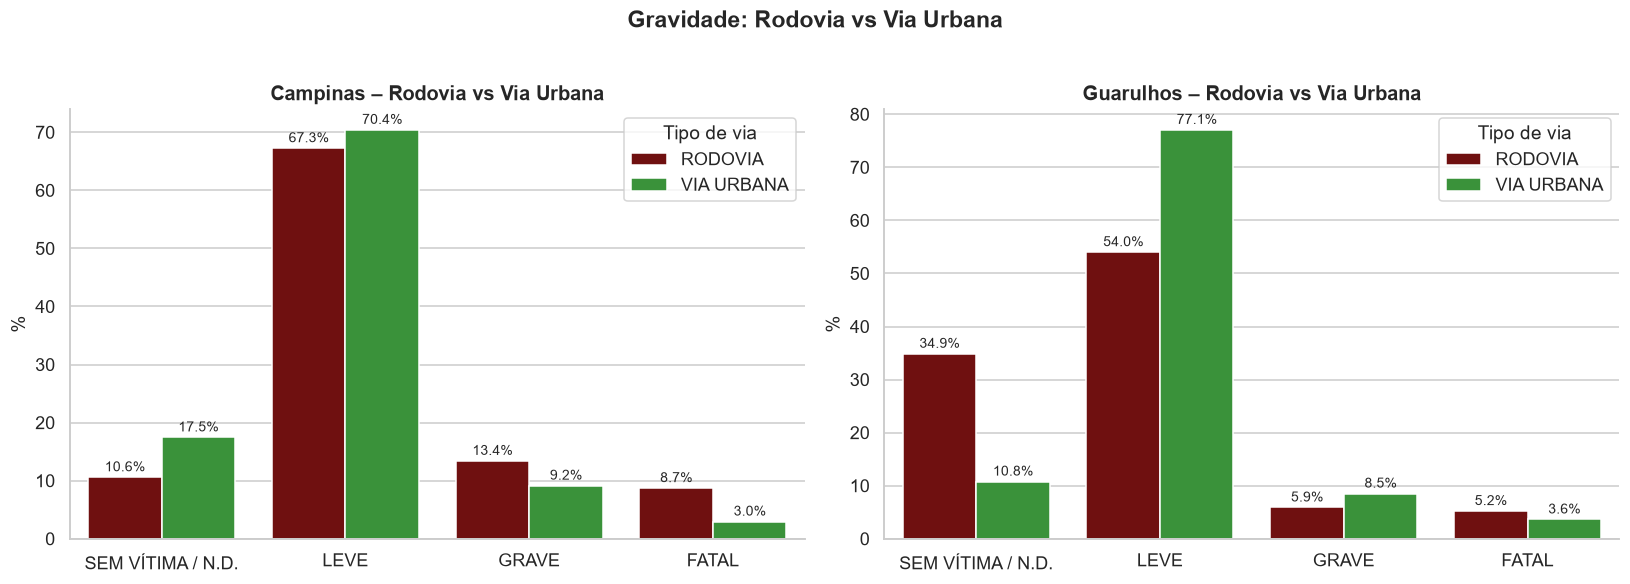

In [15]:
gv = (sin.groupby(["municipio", "grupo_via", "gravidade"]).size().reset_index(name="n"))
gv["pct"] = gv.groupby(["municipio", "grupo_via"]).n.transform(lambda x: x / x.sum() * 100)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, mun in zip(axes, MUN):
    sns.barplot(data=gv[gv.municipio == mun], x="gravidade", y="pct", hue="grupo_via",
                order=config.ORDEM_GRAVIDADE, hue_order=VIAS, palette=config.CORES_VIA, ax=ax)
    viz.rotulos_pct(ax)
    ax.set(title=f"{mun.title()} – Rodovia vs Via Urbana", xlabel="", ylabel="%"); ax.legend(title="Tipo de via")
fig.suptitle("Gravidade: Rodovia vs Via Urbana", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "04_comparativo_via_gravidade"); plt.show()

  ✔ figura salva: reports/figures/04_serie_mensal.png


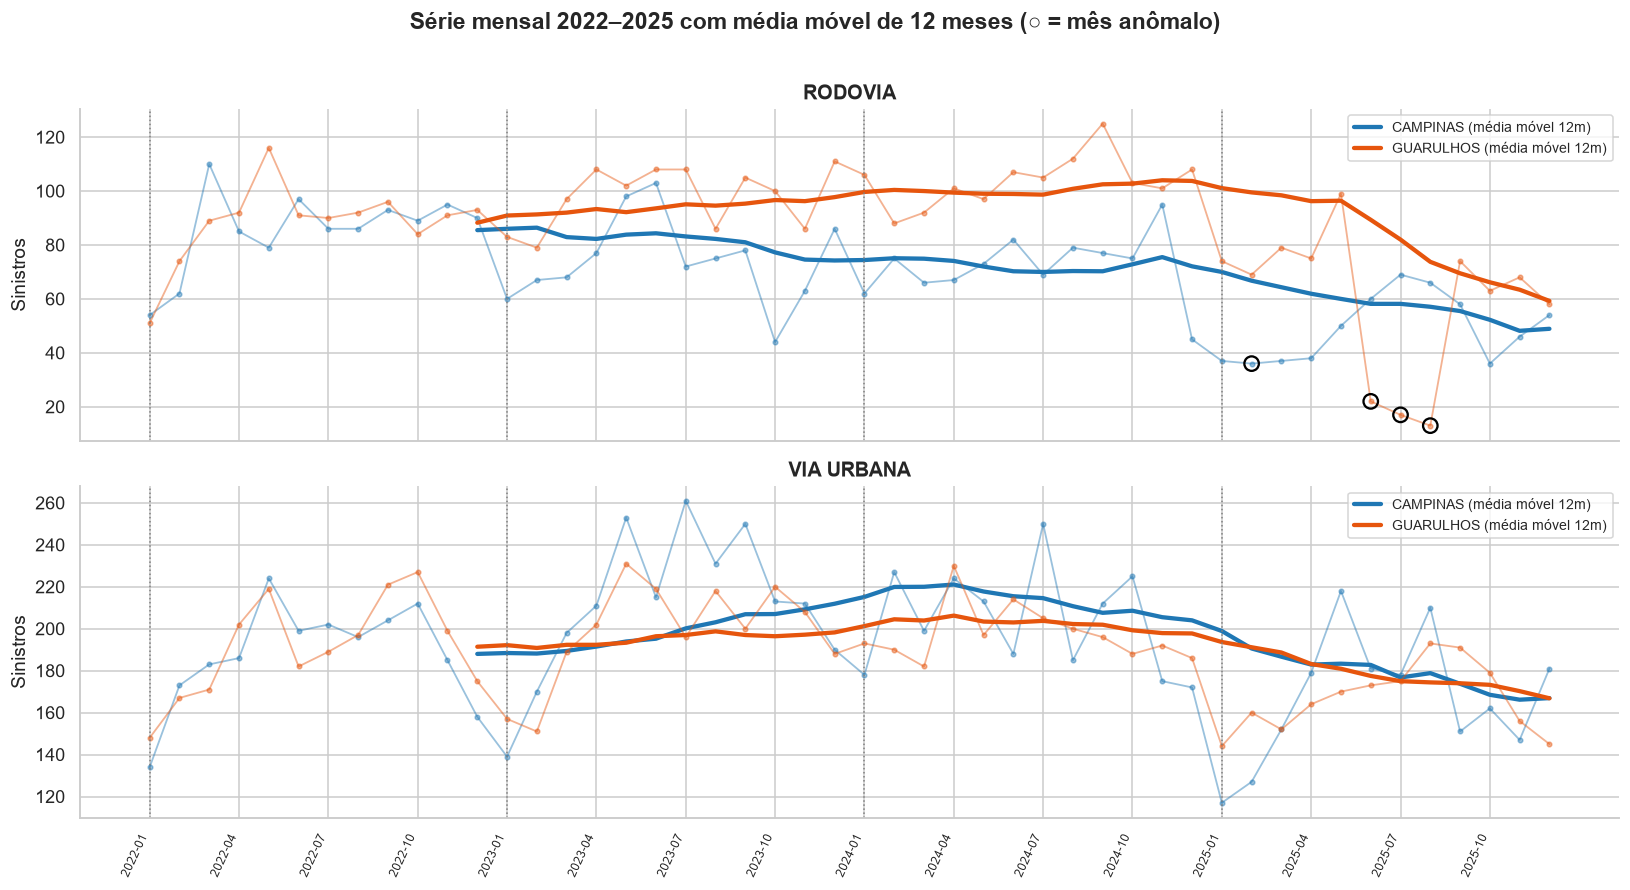

In [16]:
meses = sorted(sin.ano_mes.unique())
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, via in zip(axes, VIAS):
    for mun in MUN:
        d = (mens[(mens.grupo_via == via) & (mens.municipio == mun)]
               .set_index("ano_mes").reindex(meses, fill_value=0))
        ax.plot(meses, d.n, marker="o", ms=3, lw=1.2, alpha=.45, color=config.CORES[mun])
        ax.plot(meses, d.n.rolling(12, min_periods=12).mean(), lw=2.8, color=config.CORES[mun],
                label=f"{mun} (média móvel 12m)")
        a = d[d.anomalo.fillna(False).astype(bool)]
        ax.scatter(a.index, a.n, s=90, facecolors="none", edgecolors="black", lw=1.5, zorder=5)
    for ano in config.ANOS:
        ax.axvline(f"{ano}-01", color="gray", ls=":", lw=1)
    ax.set(title=f"{via}", ylabel="Sinistros"); ax.legend(fontsize=9)
axes[1].set_xticks(meses[::3]); axes[1].set_xticklabels(meses[::3], rotation=65, ha="right", fontsize=8)
fig.suptitle("Série mensal 2022–2025 com média móvel de 12 meses (○ = mês anômalo)",
             fontweight="bold", y=1.01)
plt.tight_layout(); viz.salvar_fig(fig, "04_serie_mensal"); plt.show()

## Resumo automático

In [17]:
print("Fatores com OR significativo (p<0,05), do maior para o menor:")
for r in or_df[or_df.significativo].sort_values("OR", ascending=False).itertuples():
    print(f"  {r.termo:<22} OR={r.OR:.2f} (IC95% {r.IC95_inf:.2f}–{r.IC95_sup:.2f}) p={r.p_valor:.4f}")
print(f"\nAUC-ROC logística (teste) = {auc_log:.3f}")

Fatores com OR significativo (p<0,05), do maior para o menor:
  Pedestre               OR=3.99 (IC95% 3.48–4.56) p=0.0000
  Motocicleta            OR=2.55 (IC95% 2.32–2.80) p=0.0000
  Veículo pesado         OR=2.33 (IC95% 2.09–2.60) p=0.0000
  Bicicleta              OR=2.32 (IC95% 1.83–2.92) p=0.0000
  Madrugada              OR=2.31 (IC95% 2.04–2.62) p=0.0000
  Choque                 OR=2.12 (IC95% 1.87–2.39) p=0.0000
  Capotamento            OR=1.45 (IC95% 1.13–1.85) p=0.0031
  Noite                  OR=1.44 (IC95% 1.30–1.59) p=0.0000
  Rodovia                OR=1.40 (IC95% 1.28–1.54) p=0.0000
  Colisão frontal        OR=1.37 (IC95% 1.23–1.53) p=0.0000
  Fim de semana          OR=1.29 (IC95% 1.18–1.40) p=0.0000
  Ano 2025               OR=1.17 (IC95% 1.05–1.30) p=0.0052
  Tombamento             OR=1.16 (IC95% 1.02–1.31) p=0.0225
  Colisão transversal    OR=0.82 (IC95% 0.73–0.92) p=0.0006
  Guarulhos              OR=0.67 (IC95% 0.62–0.72) p=0.0000
  Colisão lateral        OR=0.62 (IC95